# ACP y regresión logística para la probabilidad de superar el umbral


Usé los mismos periodos que en la red que hicieron para el entrenamiento 2023–2024, validación 2025 y prueba 2026.
el único archivo que también consideré que puede ser diferento son lo de datos_no_imputados.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
from scipy.stats import chi2
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

DATA = Path("..") / "data" / "procesados"
FIGURAS = Path("..") / "resultados" / "figuras" / "acp_logistica"
FIGURAS.mkdir(exist_ok=True)
U = {"O3": 63.0, "SO2": 20.2}        # mismos umbrales que src/train.py


Aquí usé los datos observados (sin imputar) desde 2023. Además de la limpieza de la Etapa 2, aquí aparecieron
valores meteorológicos imposibles que se convierten en faltantes: radiación > 1.5 kW/metros cuadrados (por encima de la que llega a la superficie), presión fuera de 650–780 mmHg, viento > 150 km/h y lluvia > 100 mm/h.

La lluvia se transforma con logaritmo de 1+x porque casi siempre vale 0 y tiene picos enormes, que dominarían el ACP.
La dirección del viento es circular (0° = 360°), así que se representa con su seno y coseno.

In [3]:
d = pd.read_csv(DATA / "datos_no_imputados.csv", low_memory=False)
for c in [c for c in d.columns if " (" in c]:          # columnas con unidades (problema de 2024)
    d[c.split(" (")[0]] = d[c.split(" (")[0]].fillna(d[c])
d["Fecha y hora"] = pd.to_datetime(d["Fecha y hora"])
d = d[d["Fecha y hora"] >= "2023-01-01"].copy()

# Factor de corrección de la lluvia indicado por el socio formador (SIMA):
# en estas estaciones RAINF viene en unidades 20 veces menores. Se aplica antes de la limpieza.
ESTACIONES_LLUVIA_X20 = ["CE", "NE", "NO2", "NO3", "NTE2", "SE", "SO"]
d.loc[d["Estacion"].isin(ESTACIONES_LLUVIA_X20), "RAINF"] *= 20
for v in ["O3", "SO2", "RAINF", "SR", "WSR", "RH", "PRS"]:
    d.loc[d[v] < 0, v] = np.nan
d.loc[d["RH"] > 105, "RH"] = np.nan
d["RH"] = d["RH"].clip(upper=100)
d.loc[(d["TOUT"] < -10) | (d["TOUT"] > 50), "TOUT"] = np.nan
d.loc[d["WDR"] > 360, "WDR"] = np.nan
nuevos = {"SR > 1.5": d["SR"] > 1.5, "PRS fuera de [650, 780]": (d["PRS"] < 650) | (d["PRS"] > 780),
          "WSR > 150": d["WSR"] > 150, "RAINF > 100": d["RAINF"] > 100}
print({k: int(m.sum()) for k, m in nuevos.items()})
d.loc[nuevos["SR > 1.5"], "SR"] = np.nan
d.loc[nuevos["PRS fuera de [650, 780]"], "PRS"] = np.nan
d.loc[nuevos["WSR > 150"], "WSR"] = np.nan
d.loc[nuevos["RAINF > 100"], "RAINF"] = np.nan

d["RAINF"] = np.log1p(d["RAINF"])
d["WDR_sin"] = np.sin(np.radians(d["WDR"]))
d["WDR_cos"] = np.cos(np.radians(d["WDR"]))
MET = ["TOUT", "RH", "SR", "WSR", "PRS", "RAINF", "WDR_sin", "WDR_cos"]

d["periodo"] = np.select([d["Fecha y hora"] < "2025-01-01", d["Fecha y hora"] < "2026-01-01"],
                         ["entrenamiento", "validación"], "prueba")
d["periodo"].value_counts()

{'SR > 1.5': 229, 'PRS fuera de [650, 780]': 2, 'WSR > 150': 39, 'RAINF > 100': 176}


periodo
entrenamiento    263111
validación       131378
prueba            76301
Name: count, dtype: int64

## Análisis de componentes principales


Aquí usé lo que vimos en clase que es la Prueba de esfericidad de Bartlett, que supone que  H0 es que las variables no están correlacionadas. Si se rechaza, hay correlación que resumir.
Y el Índice KMO que compara correlaciones contra correlaciones parciales. Mayor a 0.7 = aceptable; mayor a 0.8 = bueno.
Los caluclos los hice solo con los datos de entrenamiento, para no filtrar información de validación y prueba.

In [4]:
ent = d[d["periodo"] == "entrenamiento"].dropna(subset=MET)
R = ent[MET].corr()
n, p = len(ent), len(MET)

bartlett = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R))
gl = p * (p - 1) / 2
print(f"Bartlett: chi2 = {bartlett:,.0f}, gl = {gl:.0f}, p = {chi2.sf(bartlett, gl):.2g}")

Ri = np.linalg.inv(R)
parcial = -Ri / np.sqrt(np.outer(np.diag(Ri), np.diag(Ri)))
r2 = (R.values - np.eye(p)) ** 2
q2 = (parcial - np.diag(np.diag(parcial))) ** 2
print(f"KMO = {r2.sum() / (r2.sum() + q2.sum()):.3f}")

Bartlett: chi2 = 194,517, gl = 28, p = 0
KMO = 0.714


Para escoger los componentes lo que se aplicó es la regla de Kaiser, la gráfica de sedimentación y varianza acumulada ≥ 70 %.

In [5]:
valores, vectores = np.linalg.eigh(R.values)
orden = valores.argsort()[::-1]
valores, vectores = valores[orden], vectores[:, orden]
acum = valores.cumsum() / valores.sum()
print(pd.DataFrame({"valor propio": valores, "% varianza": 100 * valores / p, "% acumulado": 100 * acum},
                   index=[f"CP{i+1}" for i in range(p)]).round(2))

K = int(np.argmax(acum >= 0.70) + 1)
print("Kaiser sugiere", int((valores > 1).sum()), "componentes; con ≥ 70 % de varianza se usan K =", K)

     valor propio  % varianza  % acumulado
CP1          2.29       28.62        28.62
CP2          1.11       13.86        42.48
CP3          1.01       12.58        55.06
CP4          0.99       12.33        67.39
CP5          0.87       10.89        78.27
CP6          0.72        9.01        87.29
CP7          0.53        6.61        93.89
CP8          0.49        6.11       100.00
Kaiser sugiere 3 componentes; con ≥ 70 % de varianza se usan K = 5


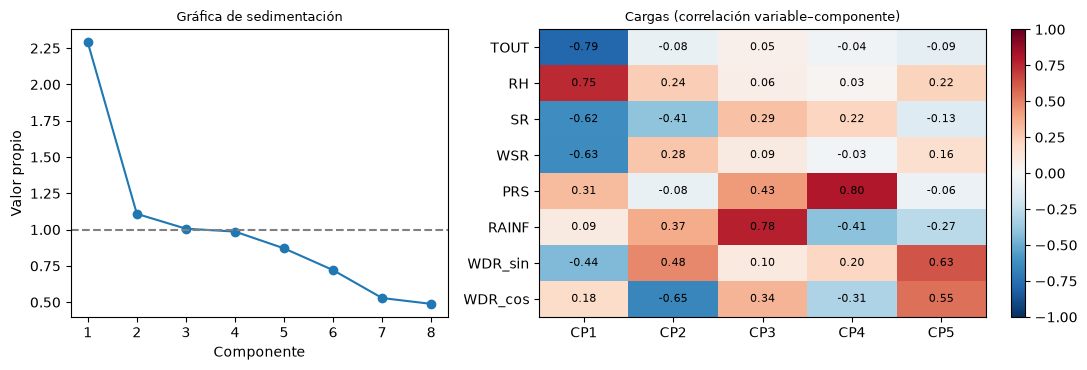

,CP1,CP2,CP3,CP4,CP5
TOUT,-0.79,-0.08,0.05,-0.04,-0.09
RH,0.75,0.24,0.06,0.03,0.22
SR,-0.62,-0.41,0.29,0.22,-0.13
WSR,-0.63,0.28,0.09,-0.03,0.16
PRS,0.31,-0.08,0.43,0.80,-0.06
RAINF,0.09,0.37,0.78,-0.41,-0.27
WDR_sin,-0.44,0.48,0.10,0.20,0.63
WDR_cos,0.18,-0.65,0.34,-0.31,0.55


In [6]:
cargas = pd.DataFrame(vectores[:, :K] * np.sqrt(valores[:K]), index=MET,
                      columns=[f"CP{i+1}" for i in range(K)])

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
ejes[0].plot(range(1, p + 1), valores, "o-")
ejes[0].axhline(1, ls="--", color="gray")
ejes[0].set_xlabel("Componente"); ejes[0].set_ylabel("Valor propio")
ejes[0].set_title("Gráfica de sedimentación", fontsize=9)
im = ejes[1].imshow(cargas.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for i in range(p):
    for j in range(K):
        ejes[1].text(j, i, f"{cargas.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ejes[1].set_xticks(range(K), cargas.columns); ejes[1].set_yticks(range(p), MET)
ejes[1].set_title("Cargas (correlación variable–componente)", fontsize=9)
fig.colorbar(im, ax=ejes[1], fraction=0.04)
fig.tight_layout()
fig.savefig(FIGURAS / "fig_acp.png", dpi=300, bbox_inches="tight")
plt.show()
cargas.round(2)

Los puntajes se calculan para todos los periodos con la media, desviación y vectores de entrenamiento,
y se dividen entre la raíz cuadrada de lamba para que cada componente tenga varianza 1. Así, cada razón de momios se lee como el efecto de subir una desviación estándar del componente.

In [7]:
media, desv = ent[MET].mean(), ent[MET].std()
CPS = [f"CP{i+1}" for i in range(K)]
puntajes = ((d[MET] - media) / desv).values @ vectores[:, :K] / np.sqrt(valores[:K])
d[CPS] = puntajes

# Ciclos diario y anual con términos de Fourier 
hora, mes = d["Fecha y hora"].dt.hour, d["Fecha y hora"].dt.month
for k in [1, 2]:
    d[f"hora_sen{k}"], d[f"hora_cos{k}"] = np.sin(2*np.pi*k*hora/24), np.cos(2*np.pi*k*hora/24)
    d[f"mes_sen{k}"], d[f"mes_cos{k}"] = np.sin(2*np.pi*k*(mes-1)/12), np.cos(2*np.pi*k*(mes-1)/12)
HORA = ["hora_sen1", "hora_cos1", "hora_sen2", "hora_cos2"]
MES = ["mes_sen1", "mes_cos1", "mes_sen2", "mes_cos2"]
estaciones = pd.get_dummies(d["Estacion"], prefix="est", drop_first=True, dtype=float)   # referencia: CE
d = pd.concat([d, estaciones], axis=1)
EST = list(estaciones.columns)
PRED = CPS + HORA + MES + EST

## Regresión logística 


Los errores estándar son varios en el día y están agrupados por fecha. Hay que considerar que las horas de un mismo día no son independientes,
y sin esta corrección los valores p saldrían demasiado pequeños.

In [8]:
def preparar(var):
    D = d.dropna(subset=MET + [var]).copy()
    D["y"] = (D[var] > U[var]).astype(int)
    return D

modelos, datos = {}, {}
for var in U:
    D = preparar(var)
    ent = D[D["periodo"] == "entrenamiento"]
    X = sm.add_constant(ent[PRED])
    dia = pd.factorize(ent["Fecha y hora"].dt.date)[0]
    m = sm.Logit(ent["y"], X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": dia})
    modelos[var], datos[var] = m, D
    print(f"{var}: n = {len(ent):,}, eventos = {ent['y'].sum():,}, parámetros = {X.shape[1]}, "
          f"eventos por parámetro = {ent['y'].sum() / X.shape[1]:.0f}, pseudo-R² = {m.prsquared:.3f}")

O3: n = 211,327, eventos = 10,208, parámetros = 28, eventos por parámetro = 365, pseudo-R² = 0.416
SO2: n = 207,633, eventos = 1,345, parámetros = 28, eventos por parámetro = 48, pseudo-R² = 0.284



RM > 1: aumenta la probabilidad de superar el umbral; RM < 1: la disminuye.

In [9]:
tablas = {}
for var, m in modelos.items():
    ic = np.exp(m.conf_int())
    tablas[var] = pd.DataFrame({"coef": m.params, "RM": np.exp(m.params),
                                "IC 95% inf": ic[0], "IC 95% sup": ic[1], "p": m.pvalues}).loc[CPS + HORA + MES]
pd.concat(tablas, axis=1).round(3)

O3                                        SO2                    \
            coef     RM IC 95% inf IC 95% sup      p   coef     RM IC 95% inf   
CP1       -1.575  0.207      0.160      0.268  0.000 -0.855  0.425      0.365   
CP2       -1.843  0.158      0.073      0.342  0.000 -1.369  0.254      0.179   
CP3       -3.467  0.031      0.006      0.155  0.000 -2.735  0.065      0.031   
CP4        1.436  4.204      1.841      9.599  0.001  1.840  6.298      4.300   
CP5        0.937  2.553      1.459      4.467  0.001  1.168  3.216      2.514   
hora_sen1 -2.722  0.066      0.037      0.118  0.000 -0.531  0.588      0.448   
hora_cos1 -2.096  0.123      0.075      0.202  0.000 -0.888  0.411      0.319   
hora_sen2  0.280  1.323      1.009      1.735  0.043  0.063  1.065      0.904   
hora_cos2  0.392  1.480      1.235      1.775  0.000  0.090  1.094      0.921   
mes_sen1   0.021  1.021      0.856      1.218  0.817 -0.449  0.638      0.528   
mes_cos1  -0.288  0.749      0.582      0.964  0.025  0.730  2.075      1.717   
mes_sen2  -0.102  0.903      0.757      1.077  0.255  0.332  1.394      1.186   
mes_cos2  -0.599  0.549      0.457      0.660  0.000  0.124  1.132      0.951   

                             
          IC 95% sup      p  
CP1            0.495  0.000  
CP2            0.361  0.000  
CP3            0.135  0.000  
CP4            9.223  0.000  
CP5            4.113  0.000  
hora_sen1      0.771  0.000  
hora_cos1      0.530  0.000  
hora_sen2      1.256  0.451  
hora_cos2      1.300  0.304  
mes_sen1       0.772  0.000  
mes_cos1       2.509  0.000  
mes_sen2       1.640  0.000  
mes_cos2       1.347  0.162

Los supuestos que se tienen que cumplir son el de multicolinealidad (VIF <5), el tamaño de muestra (que sea mayor a 10 evectos por parámetros) y la independencia (autocorrelación de los residuos con la hora anterior dentro de cada estación)

In [10]:
for var, m in modelos.items():
    D = datos[var]; ent = D[D["periodo"] == "entrenamiento"]
    X = sm.add_constant(ent[PRED])
    vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=PRED)
    p_hat = m.predict(X)
    r = (ent["y"] - p_hat) / np.sqrt(p_hat * (1 - p_hat))
    ac = ent.assign(r=r).sort_values(["Estacion", "Fecha y hora"]).groupby("Estacion")["r"].apply(lambda s: s.autocorr(1))
    print(f"{var}: VIF máximo = {vif.max():.2f} ({vif.idxmax()}); "
          f"autocorrelación de residuos (mediana por estación) = {ac.median():.2f}")

O3: VIF máximo = 4.65 (CP4); autocorrelación de residuos (mediana por estación) = 0.48
SO2: VIF máximo = 4.51 (CP4); autocorrelación de residuos (mediana por estación) = 0.21


Se hace la Prueba de razón de verosimilitudes por bloque, se quita un bloque completo (meteorología, hora, mes o estación) y se mide cuánto empeora el ajuste.
Osea entre más grande la chi cuadrada, indica un bloque más importante.

In [11]:
filas = []
for var in U:
    D = datos[var]; ent = D[D["periodo"] == "entrenamiento"]
    X = sm.add_constant(ent[PRED])
    completo = sm.Logit(ent["y"], X).fit(disp=0)
    for nombre, bloque in [("Meteorología (CP)", CPS), ("Hora", HORA), ("Mes", MES), ("Estación", EST)]:
        reducido = sm.Logit(ent["y"], X.drop(columns=bloque)).fit(disp=0)
        lr = 2 * (completo.llf - reducido.llf)
        filas.append({"contaminante": var, "bloque": nombre, "chi2": lr, "gl": len(bloque), "p": chi2.sf(lr, len(bloque))})
importancia = pd.DataFrame(filas)
importancia.round(1)

,contaminante,bloque,chi2,gl,p
0,O3,Meteorología (CP),6160.1,5,0.0
1,O3,Hora,5413.3,4,0.0
2,O3,Mes,1261.5,4,0.0
3,O3,Estación,1650.4,14,0.0
4,SO2,Meteorología (CP),409.2,5,0.0
5,SO2,Hora,183.3,4,0.0
6,SO2,Mes,316.4,4,0.0
7,SO2,Estación,1145.9,14,0.0


Para saber el peso de las variables, los coeficientes de los componentes se regresan a las variables originales
(efecto de subir una desviación estándar cada variable, manteniendo las demás). Es una aproximación, porque el modelo solo usa los K componentes, que en este caso pues son 3.

In [12]:
efecto = {}
for var, m in modelos.items():
    beta_cp = m.params[CPS].values
    efecto[var] = vectores[:, :K] / np.sqrt(valores[:K]) @ beta_cp
pd.DataFrame(efecto, index=MET).round(2).sort_values("O3", key=abs, ascending=False)

,O3,SO2
RAINF,-4.24,-3.72
RH,-0.86,-0.41
PRS,-0.45,0.23
TOUT,0.36,0.08
SR,0.27,0.17
WSR,-0.21,-0.19
WDR_sin,0.14,0.53
WDR_cos,-0.06,-0.02


se  validan con 2025 y 2026

Brier: error cuadrático medio de la probabilidad (menor es mejor).
Brier skill score (BSS): La referencia es la frecuencia histórica de cada estación en entrenamiento. BSS > 0 indica que el modelo aporta información.
AUC: probabilidad de que un caso con excedencia reciba una probabilidad mayor que uno sin excedencia (0.5 = azar).
Discriminante lineal (LDA):comparación, como se indicó en la metodología.

In [13]:
filas, calib = [], {}
for var, m in modelos.items():
    D = datos[var]; ent = D[D["periodo"] == "entrenamiento"]
    ref = ent.groupby("Estacion")["y"].mean()
    lda = LinearDiscriminantAnalysis().fit(ent[PRED], ent["y"])
    for per in ["validación", "prueba"]:
        T = D[D["periodo"] == per]
        p_log = m.predict(sm.add_constant(T[PRED], has_constant="add"))
        p_ref = T["Estacion"].map(ref)
        p_lda = lda.predict_proba(T[PRED])[:, 1]
        b_log, b_ref = brier_score_loss(T["y"], p_log), brier_score_loss(T["y"], p_ref)
        filas.append({"contaminante": var, "periodo": per, "n": len(T), "eventos": int(T["y"].sum()),
                      "Brier logística": b_log, "Brier referencia": b_ref, "BSS": 1 - b_log / b_ref,
                      "AUC logística": roc_auc_score(T["y"], p_log), "AUC referencia": roc_auc_score(T["y"], p_ref),
                      "Brier LDA": brier_score_loss(T["y"], p_lda), "AUC LDA": roc_auc_score(T["y"], p_lda)})
        calib[(var, per)] = pd.DataFrame({"pred": p_log.values, "obs": T["y"].values})
validacion = pd.DataFrame(filas)
validacion.round(4)

,contaminante,periodo,n,eventos,Brier logística,Brier referencia,BSS,AUC logística,AUC referencia,Brier LDA,AUC LDA
0,O3,validación,92476,6394,0.0440,0.0640,0.3136,0.9435,0.6222,0.0467,0.9322
1,O3,prueba,39261,2216,0.0391,0.0527,0.2576,0.9402,0.6424,0.0397,0.9319
2,SO2,validación,90559,1106,0.0114,0.0118,0.0348,0.8598,0.8375,0.0142,0.8527
3,SO2,prueba,39504,151,0.0037,0.0038,0.0171,0.9018,0.7701,0.0037,0.8795


Calibración del modelo, aquí hay que ver si los puntos caen sobre la diagonal

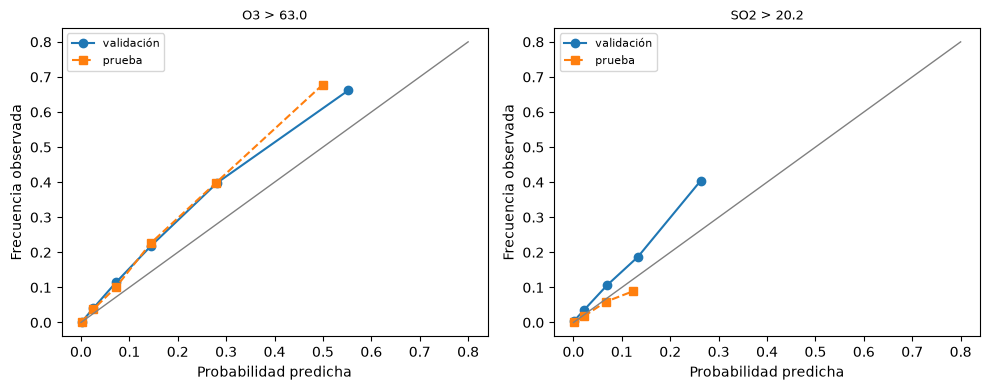

In [14]:
cortes = [0, 0.01, 0.05, 0.1, 0.2, 0.4, 1]
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, var in zip(ejes, U):
    for per, marca in [("validación", "o-"), ("prueba", "s--")]:
        c = calib[(var, per)]
        g = c.groupby(pd.cut(c["pred"], cortes), observed=True).agg(pred=("pred", "mean"), obs=("obs", "mean"), n=("obs", "size"))
        g = g[g["n"] >= 30]
        eje.plot(g["pred"], g["obs"], marca, label=per)
    eje.plot([0, 0.8], [0, 0.8], color="gray", lw=1)
    eje.set_xlabel("Probabilidad predicha"); eje.set_ylabel("Frecuencia observada")
    eje.set_title(f"{var} > {U[var]}", fontsize=9); eje.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "fig_calibracion.png", dpi=300, bbox_inches="tight")
plt.show()